<a href="https://colab.research.google.com/github/FarahMandili/Firstcode_NN/blob/main/NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import importlib.metadata as metadata

print("Python:", sys.version)

for package in ["torch", "torchvision", "sympy"]:
    print(package, metadata.version(package))

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
torch 2.15.0
torchvision 0.29.2
sympy 1.14.0


In [2]:
%pip install --upgrade --force-reinstall torch torchvision sympy

  Using cached torch-2.15.0-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (36 kB)
  Using cached torchvision-0.29.2-py3-none-manylinux_2_28_x86_64.whl.metadata (5.7 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached filelock-4.3.0-py3-none-any.whl.metadata (2.3 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached cuda_toolkit-13.2.2-py2.py3-none-any.whl.metadata (20 kB)
  Using cached cuda_bindings-13.5.0-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (2.5 kB)
  Using cached nvidia_cudnn_cu13-9.26.0.51-py3-none-manylinux_2_27_x86_64.whl.metadata (1.9 kB)
  Using cached nvidia_cusparselt_cu13-0.8.1-py3-none-manylinux2014_x86_64.whl.metadata

In [1]:
import torch #Library
import torch.nn as nn #Build neural network layers
import torch.optim as optim #Update model weights during training
import torchvision #Image datasets and vision tools
import torchvision.transforms as transforms #Preprocess images
from torch.utils.data import DataLoader #Load data in batches

In [2]:
transform = transforms.Compose([ #Convert the image (0-255) into a tensor (0-1) and normalize the tensor values
    transforms.ToTensor(), #change the image format into a tensor with dimensions (c,h,w)
    transforms.Normalize((0.1307,), (0.3081,)) #Normalises the tensor using the specified mean and standard deviation
])

In [3]:
train_dataset= torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset= torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

torch.Size([1, 28, 28]) 5


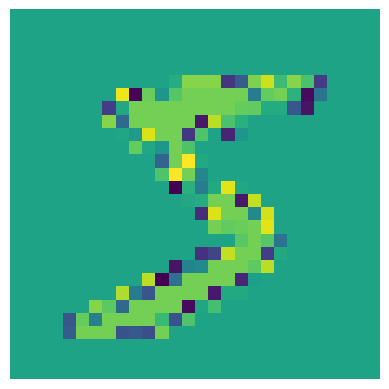

In [4]:
print(train_dataset[0][0].shape, train_dataset[0][1])
#data type:
#scaler(676) -> shape:1x1 ->1
#vector([3,2,22,0.4]) -> shape:1x4 ->4
#matrix([1,2],[6,2]) -> shape:2x2

from torchvision.transforms import ToPILImage

pil_image = ToPILImage()(train_dataset[0][0])

import matplotlib.pyplot as plt

plt.imshow(pil_image)
plt.axis("off")
plt.show()


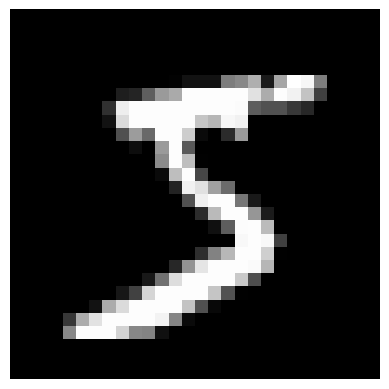

In [5]:
import matplotlib.pyplot as plt
from torchvision.transforms import ToPILImage

image = train_dataset[0][0]  # Normalized tensor: (C, H, W)

# Reverse normalization
image = image * 0.3081 + 0.1307

# Convert to PIL image
pil_image = ToPILImage()(image.clamp(0, 1))

plt.imshow(pil_image, cmap="gray")
plt.axis("off")
plt.show()

In [6]:
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True) #learn and update weights
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False) # evaluate performance
# batch_size= how many images per batch will be involved
# shuffle= random rearrange the data at the start of each epoch or not

In [7]:
class Classifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.linear1 = nn.Linear(784, 128)

        self.relu = nn.ReLU()

        self.linear2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.flatten(x)

        x = self.linear1(x)

        x = self.relu(x)

        x = self.linear2(x)

        return x

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Using {device}')

model = Classifier().to(device)# it is only called __init__()

loss_function = nn.CrossEntropyLoss() #loss function measures how far the model's predictions are from the correct labels #SoftMax inside this function####
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) #The learning rate controls the size Of the weight updates. If it is too large, training may become unstable; if too small, learning may be slow

Using cpu


In [9]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = Classifier().to(device)

loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [10]:
from os import pread
def train_epoch(model, train_loader, loss_function, optimizer, device):
    model.train() #the model is in training mode. This matters for layers such as dropout and batch normalisation
    running_loss = 0.0 #accumulates the loss over batches
    correct = 0 #counts correctly classified images
    total = 0 #counts the images processed

    for batch_idx, (data, target) in enumerate(train_loader):  #the batch number starting from 0
        data, target = data.to(device), target.to(device)#groundtruth==labels==target

    optimizer.zero_grad() #clear old gradients
    output = model(data) #forward pass it is called forward(self, x)
    #output = model.forward(data) #forward pass it is called forward(self, x)
    loss = loss_function(output, target) #calculate loss, smaller loss indicates better predictions
    loss.backward() #backpropagation
    optimizer.step() #update weights

    running_loss += loss.item()
    _, predicted = output.max(1) #finds the highest-scoring class for each image
    total += target.size(0) #gives the number of images in the batch
    correct += predicted.eq(target).sum().item() #counts the correct predictions

    if batch_idx % 100 == 0 and batch_idx > 0:
      avg_loss = running_loss / 100    #calculates the average loss across the last 100 batches
      accuracy = 100. * correct / total
      print(f'[{batch_idx *64}/{60000}]'
            f' Loss: {avg_loss:.3f} | Accuracy: {accuracy:.1f}%')
      running_loss = 0.0


# train_epoch(model, train_loader, loss_function, optimizer, device)


Create a validation dataset

In [11]:
from torch.utils.data import random_split

full_train_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

# Split training data: 90% training, 10% validation
train_size = int(0.9 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size]
)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=1000, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=1000, shuffle=False
)

In [12]:
def evaluate(model, test_loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad(): #no grad, no updating for the model's weights
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _,predicted = outputs.max(1) #selects the highest-scoring class for each image
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
    return 100. * correct / total #Calculates the overall test accuracy as a percentage

Calculate training loss and accuracy

In [13]:
def train_epoch(model, loader, criterion, optimizer, device):

    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for data, targets in loader:

        data, targets = data.to(device), targets.to(device)

        optimizer.zero_grad()

        outputs = model(data)

        loss = criterion(outputs, targets)

        loss.backward()

        optimizer.step()

        batch_size = targets.size(0)

        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)

        total_correct += (predictions == targets).sum().item()

        total_samples += batch_size

    average_loss = total_loss / total_samples

    accuracy = 100 * total_correct / total_samples

    return average_loss, accuracy

Calculate validation loss and accuracy

In [14]:
def evaluate(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():

        for data, targets in loader:

            data, targets = data.to(device), targets.to(device)

            outputs = model(data)

            loss = criterion(outputs, targets)

            batch_size = targets.size(0)

            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            total_correct += (predictions == targets).sum().item()

            total_samples += batch_size

    average_loss = total_loss / total_samples

    accuracy = 100 * total_correct / total_samples

    return average_loss, accuracy

Store the learning history

In [15]:
num_epochs = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

In [16]:
for epoch in range(num_epochs):

    train_loss, train_accuracy = train_epoch(
        model, train_loader, loss_function, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, loss_function, device
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch+1}/{num_epochs} "
        f"Train Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Validation Loss: {val_loss:.4f} "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

Epoch 1/10 Train Loss: 0.3233 Train Accuracy: 90.68% Validation Loss: 0.1815 Validation Accuracy: 94.52%
Epoch 2/10 Train Loss: 0.1434 Train Accuracy: 95.73% Validation Loss: 0.1307 Validation Accuracy: 96.00%
Epoch 3/10 Train Loss: 0.0992 Train Accuracy: 97.05% Validation Loss: 0.1095 Validation Accuracy: 96.67%
Epoch 4/10 Train Loss: 0.0758 Train Accuracy: 97.72% Validation Loss: 0.0988 Validation Accuracy: 97.10%
Epoch 5/10 Train Loss: 0.0585 Train Accuracy: 98.26% Validation Loss: 0.0946 Validation Accuracy: 97.28%
Epoch 6/10 Train Loss: 0.0489 Train Accuracy: 98.49% Validation Loss: 0.0923 Validation Accuracy: 97.22%
Epoch 7/10 Train Loss: 0.0414 Train Accuracy: 98.74% Validation Loss: 0.0921 Validation Accuracy: 97.30%
Epoch 8/10 Train Loss: 0.0332 Train Accuracy: 99.05% Validation Loss: 0.0867 Validation Accuracy: 97.48%
Epoch 9/10 Train Loss: 0.0280 Train Accuracy: 99.16% Validation Loss: 0.0960 Validation Accuracy: 97.20%
Epoch 10/10 Train Loss: 0.0229 Train Accuracy: 99.33% V

Find the minimum observed loss

In [17]:
import numpy as np

best_train_loss = min(history["train_loss"])

best_val_loss = min(history["val_loss"])

best_train_epoch = np.argmin(history["train_loss"]) + 1

best_val_epoch = np.argmin(history["val_loss"]) + 1

print("Minimum training loss:", best_train_loss)

print("Minimum validation loss:", best_val_loss)

print("Best training epoch:", best_train_epoch)

print("Best validation epoch:", best_val_epoch)

Minimum training loss: 0.022862053586377037
Minimum validation loss: 0.08665598059693973
Best training epoch: 10
Best validation epoch: 8


Plot training and validation loss

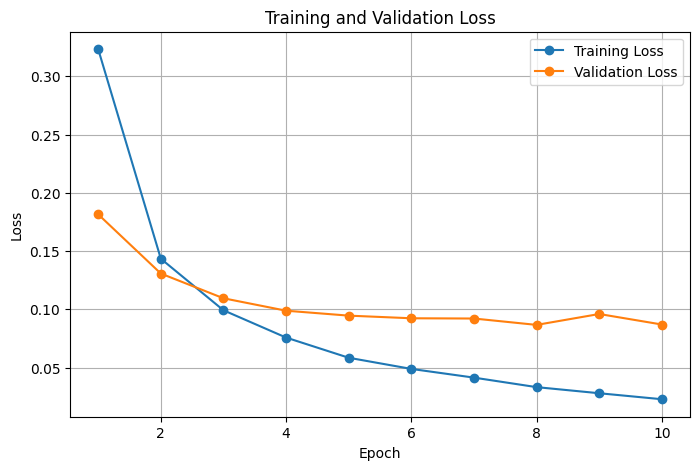

In [18]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.savefig("loss_learning_curve.png")

plt.show()

Plot training and validation accuracy

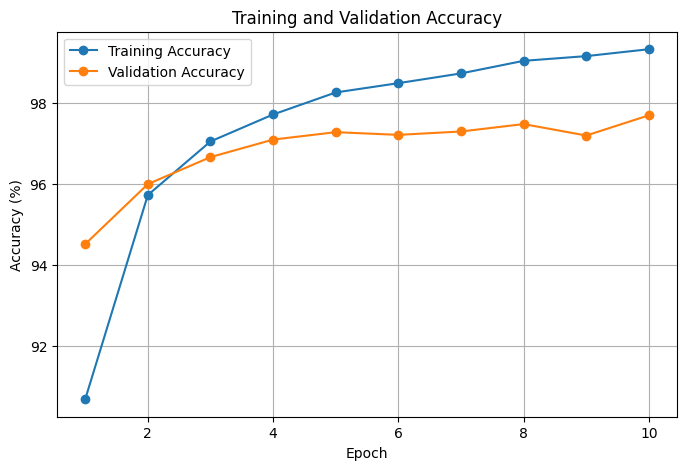

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.savefig("accuracy_learning_curve.png")

plt.show()

Save the best model

In [20]:
import copy

best_val_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(num_epochs):

    # Training and validation code goes here

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_model_state,
            "best_mnist_model.pth"
        )

Evaluate the final model on test data

In [21]:
model.load_state_dict(best_model_state)

test_loss, test_accuracy = evaluate(
    model,
    test_loader,
    loss_function,
    device
)

print("Final Test Loss:", test_loss)
print("Final Test Accuracy:", test_accuracy)

Final Test Loss: 0.07967524286359548
Final Test Accuracy: 97.78


Save results in a CSV file

In [22]:
import csv

with open("training_history.csv", "w", newline="") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Epoch",
        "Training Loss",
        "Validation Loss",
        "Training Accuracy",
        "Validation Accuracy"
    ])

    for i in range(num_epochs):

        writer.writerow([
            i + 1,
            history["train_loss"][i],
            history["val_loss"][i],
            history["train_accuracy"][i],
            history["val_accuracy"][i]
        ])

Display a digit in grayscale

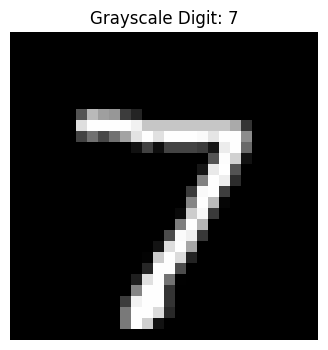

In [23]:
import matplotlib.pyplot as plt

# Get one image and its actual label
image, label = test_dataset[0]

# Reverse normalisation
image_display = image * 0.3081 + 0.1307

plt.figure(figsize=(4, 4))

plt.imshow(image_display.squeeze(), cmap='gray')

plt.title(f"Grayscale Digit: {label}")

plt.axis('off')
plt.show()

Display the same digit in colour

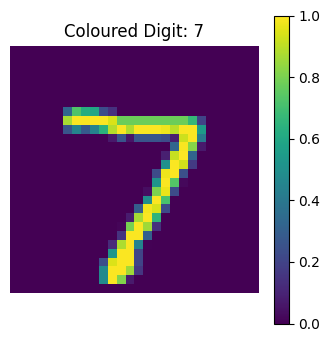

In [24]:
plt.figure(figsize=(4, 4))

plt.imshow(image_display.squeeze(), cmap='viridis')

plt.title(f"Coloured Digit: {label}")

plt.axis('off')
plt.colorbar()
plt.show()

Compare grayscale and colour side by side

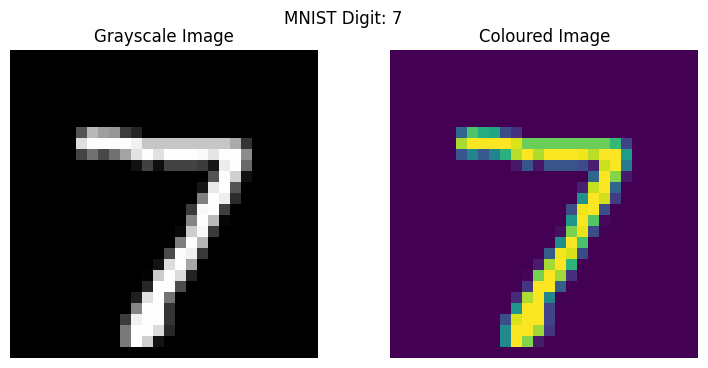

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

# Grayscale
axes[0].imshow(image_display.squeeze(), cmap='gray')
axes[0].set_title("Grayscale Image")
axes[0].axis('off')

# Colour
axes[1].imshow(image_display.squeeze(), cmap='viridis')
axes[1].set_title("Coloured Image")
axes[1].axis('off')

plt.suptitle(f"MNIST Digit: {label}")

plt.show()

Display the NN prediction as well

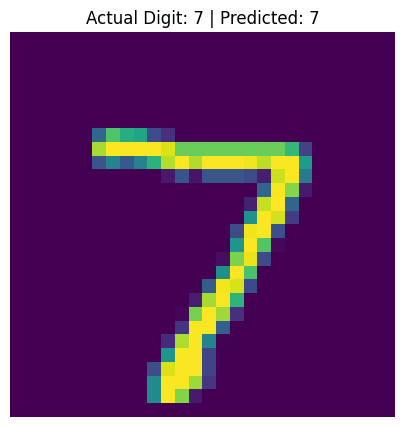

In [26]:
model.eval()

with torch.no_grad():

    input_image = image.unsqueeze(0).to(device)

    output = model(input_image)

    prediction = output.argmax(dim=1).item()

plt.figure(figsize=(5, 5))

plt.imshow(image_display.squeeze(), cmap='viridis')

plt.title(
    f"Actual Digit: {label} | Predicted: {prediction}"
)

plt.axis('off')
plt.show()

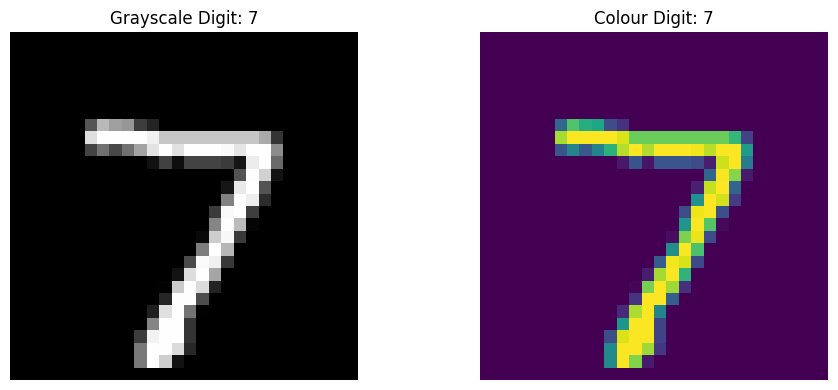

In [27]:
import matplotlib.pyplot as plt
from torchvision.transforms import ToPILImage

# Select an image from the test dataset
image, label = test_dataset[0]

# Reverse normalisation
image_display = image * 0.3081 + 0.1307

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Grayscale
axes[0].imshow(image_display.squeeze(), cmap='gray')
axes[0].set_title(f'Grayscale Digit: {label}')
axes[0].axis('off')

# Colour
axes[1].imshow(image_display.squeeze(), cmap='viridis')
axes[1].set_title(f'Colour Digit: {label}')
axes[1].axis('off')

plt.tight_layout()
plt.show()

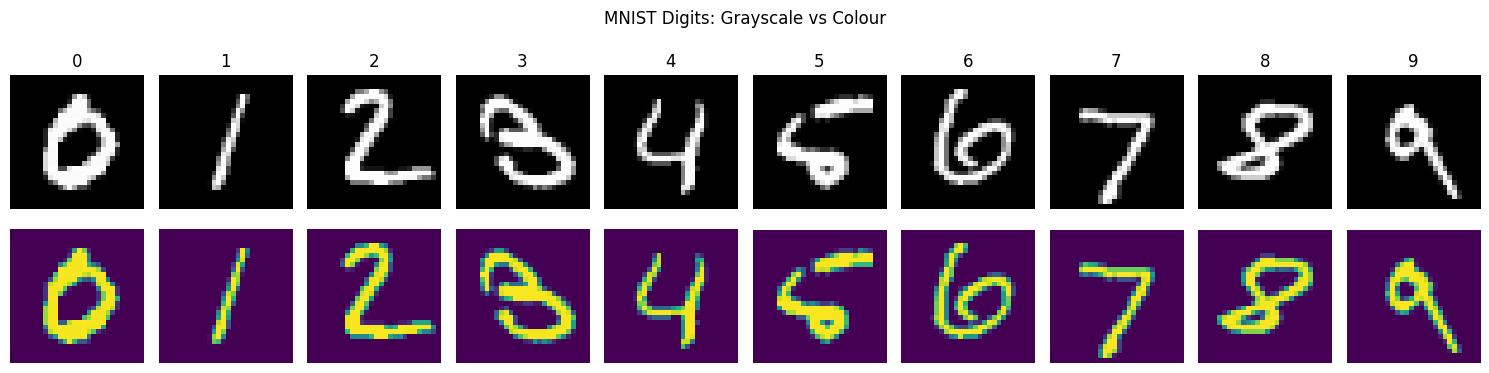

In [28]:
fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for digit in range(10):

    # Find an image corresponding to each digit
    index = next(
        i for i in range(len(test_dataset))
        if test_dataset[i][1] == digit
    )

    image, label = test_dataset[index]

    # Reverse normalisation
    image_display = image * 0.3081 + 0.1307

    # First row: grayscale
    axes[0, digit].imshow(
        image_display.squeeze(), cmap='gray'
    )
    axes[0, digit].set_title(str(label))
    axes[0, digit].axis('off')

    # Second row: colour
    axes[1, digit].imshow(
        image_display.squeeze(), cmap='viridis'
    )
    axes[1, digit].axis('off')

axes[0, 0].set_ylabel("Grayscale")
axes[1, 0].set_ylabel("Colour")

plt.suptitle("MNIST Digits: Grayscale vs Colour")
plt.tight_layout()
plt.show()

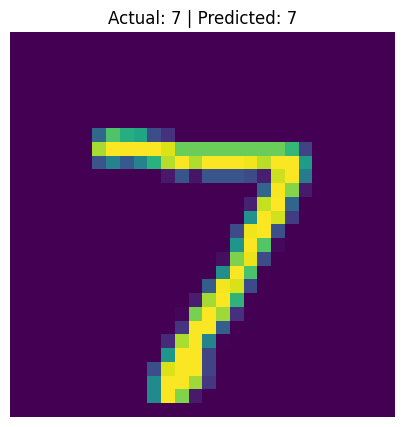

In [29]:
model.eval()

image, label = test_dataset[0]

with torch.no_grad():

    input_image = image.unsqueeze(0).to(device)

    output = model(input_image)

    prediction = output.argmax(dim=1).item()

# Reverse normalisation
image_display = image * 0.3081 + 0.1307

plt.figure(figsize=(5, 5))

plt.imshow(image_display.squeeze(), cmap='viridis')

plt.title(
    f"Actual: {label} | Predicted: {prediction}"
)

plt.axis('off')
plt.show()

Balance accuracy

In [30]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Evaluate the trained model
model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():
    for data, targets in test_loader:
        data = data.to(device)

        outputs = model(data)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(targets.numpy())

# Calculate metrics
accuracy = accuracy_score(all_targets, all_predictions)

f1 = f1_score(
    all_targets,
    all_predictions,
    average="macro"
)

balanced_acc = balanced_accuracy_score(
    all_targets,
    all_predictions
)

print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Macro F1-score: {f1:.4f}")
print(f"Balanced Accuracy: {balanced_acc * 100:.2f}%")

# Detailed results for each digit
print("\nClassification Report:")
print(classification_report(
    all_targets,
    all_predictions,
    zero_division=0
))


Test Accuracy: 97.78%
Macro F1-score: 0.9777
Balanced Accuracy: 97.78%

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.98      1032
           3       0.99      0.97      0.98      1010
           4       0.97      0.98      0.98       982
           5       0.97      0.99      0.98       892
           6       0.98      0.98      0.98       958
           7       0.98      0.97      0.98      1028
           8       0.98      0.96      0.97       974
           9       0.97      0.96      0.96      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000

